# Penerapan Pengolahan Citra Digital untuk Segmentasi dan Analisis Pembuluh Darah Retina
**Mata Kuliah:** Analisis Data Citra Biomedik  
**Dataset:** DRIVE (Digital Retinal Images for Vessel Extraction)  
**Kelompok 5:**
* **Anggota A (Nad):** Nadhifa Sakha Tri Yasmin (NIM: L0224036) — Peran: Pengembangan, evaluasi, analisis, dan penulisan
* **Anggota B (Kayo):** Kayla Maharani Muzaki (NIM: L0224050) — Peran: Pengembangan, evaluasi, analisis, dan penulisan

---

## 1. Pendahuluan dan Garis Besar Percobaan
Proyek ini bertujuan menerapkan rangkaian metode pengolahan citra digital klasik untuk memisahkan struktur pembuluh darah retina dari latar belakang pada citra fundus, mengukur proporsi area pembuluh terhadap retina, serta mengevaluasi kualitas segmentasi secara objektif terhadap ground truth manual.

### Tiga Alur Percobaan:
1. **Percobaan A (Baseline):** Kanal Hijau $\rightarrow$ Morfologi Bottom-Hat $\rightarrow$ Thresholding Otsu (dalam FOV).
2. **Percobaan B:** Kanal Hijau $\rightarrow$ CLAHE $\rightarrow$ Filter Median $\rightarrow$ Bottom-Hat $\rightarrow$ Thresholding Otsu (dalam FOV).
3. **Percobaan C (Alur Lengkap):** Alur B $\rightarrow$ Morfologi Closing Biner $\rightarrow$ Penghapusan Komponen Kecil (Small Object Removal).

> **Catatan Kerja Bersama (Minggu 1):**
> Fokus Minggu 1 adalah meletakkan fondasi yang kokoh: audit validitas seluruh data (pasangan file, resolusi, integritas mask biner), penetapan split data 12 pengembangan / 8 penilaian dengan *seed* 42, implementasi fungsi evaluasi metrik dalam FOV beserta unit testing, serta eksekusi awal Percobaan A pada 12 data pengembangan.

## 2. Persiapan Lingkungan dan Konfigurasi Direktori
*(Bagian Nad & Kayo)*  
Pada bagian ini dilakukan import pustaka Python, pengaturan konstanta global, path relatif yang portabel, serta penyiapan folder penyimpanan hasil keluaran (`hasil/tabel` dan `hasil/gambar`).

In [1]:
import os
import random
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Konfigurasi Reproduksibilitas (Seed)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Konfigurasi Path Relatif Portabel
# Jalankan notebook dari folder repo. Jika berbeda (misalnya di Colab),
# ganti BASE_DIR dengan lokasi folder retinal-vessel-segmentation.
BASE_DIR = os.getcwd()
RADIUS_BH = 5  # Radius awal minggu 1, belum hasil pemilihan parameter
DATASETS_DIR = os.path.join(BASE_DIR, "datasets retina drive")
if not os.path.isdir(DATASETS_DIR):
    raise FileNotFoundError("Folder dataset tidak ditemukan. Periksa BASE_DIR pada sel ini.")
TRAIN_IMG_DIR = os.path.join(DATASETS_DIR, "training", "images")
TRAIN_MAN_DIR = os.path.join(DATASETS_DIR, "training", "1st_manual")
TRAIN_MSK_DIR = os.path.join(DATASETS_DIR, "training", "mask")

TEST_IMG_DIR = os.path.join(DATASETS_DIR, "test", "images")
TEST_MSK_DIR = os.path.join(DATASETS_DIR, "test", "mask")

OUTPUT_TABEL_DIR = os.path.join(BASE_DIR, "hasil", "tabel")
OUTPUT_GAMBAR_DIR = os.path.join(BASE_DIR, "hasil", "gambar")

os.makedirs(OUTPUT_TABEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_GAMBAR_DIR, exist_ok=True)

print("Path Konfigurasi Berhasil Disiapkan:")
print(" - Direktori Data Training :", os.path.exists(TRAIN_IMG_DIR))
print(" - Direktori Data Test     :", os.path.exists(TEST_IMG_DIR))
print(" - Direktori Tabel Output  :", OUTPUT_TABEL_DIR)
print(" - Direktori Gambar Output :", OUTPUT_GAMBAR_DIR)

Path Konfigurasi Berhasil Disiapkan:
 - Direktori Data Training : True
 - Direktori Data Test     : True
 - Direktori Tabel Output  : d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\tabel
 - Direktori Gambar Output : d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\gambar


## 3. Pemeriksaan dan Audit Data (Manifest Data)
*(Tanggung jawab utama: Kayo)*  
Sebelum menjalankan pemrosesan, dilakukan verifikasi menyeluruh terhadap 20 pasangan citra training dan 20 pasangan citra test:
1. Kesesuaian ID dan keberadaan file (tidak ada file hilang).
2. Dimensi piksel citra dan mask (harus seragam $565 \times 584$ lebar $\times$ tinggi).
3. Nilai unik mask FOV dan ground truth pembuluh darah (harus bernilai biner $\{0, 255\}$ atau $\{0, 1\}$).

Hasil audit disimpan ke dalam `hasil/tabel/manifest_data.csv`.

In [2]:
manifest_rows = []

# Audit Data Training (ID: 21 s.d. 40)
for i in range(21, 41):
    id_str = str(i)
    f_img = f"{id_str}_training.tif"
    f_man = f"{id_str}_manual1.gif"
    f_msk = f"{id_str}_training_mask.gif"
    
    p_img = os.path.join(TRAIN_IMG_DIR, f_img)
    p_man = os.path.join(TRAIN_MAN_DIR, f_man)
    p_msk = os.path.join(TRAIN_MSK_DIR, f_msk)
    
    exists_all = os.path.exists(p_img) and os.path.exists(p_man) and os.path.exists(p_msk)
    im = Image.open(p_img) if os.path.exists(p_img) else None
    man = Image.open(p_man) if os.path.exists(p_man) else None
    msk = Image.open(p_msk) if os.path.exists(p_msk) else None
    
    size_ok = (im.size == (565, 584)) and (man.size == (565, 584)) and (msk.size == (565, 584)) if exists_all else False
    man_vals = sorted(list(np.unique(np.array(man)))) if exists_all else []
    msk_vals = sorted(list(np.unique(np.array(msk)))) if exists_all else []
    vals_ok = (man_vals in [[0, 255], [0, 1]]) and (msk_vals in [[0, 255], [0, 1]])
    
    status = "Valid" if (exists_all and size_ok and vals_ok) else "Invalid"
    manifest_rows.append({
        "set": "training",
        "id": id_str,
        "file_citra": f_img,
        "file_mask_fov": f_msk,
        "file_gt_manual": f_man,
        "dimensi_citra": f"{im.size[0]}x{im.size[1]}" if im else "-",
        "dimensi_fov": f"{msk.size[0]}x{msk.size[1]}" if msk else "-",
        "dimensi_gt": f"{man.size[0]}x{man.size[1]}" if man else "-",
        "nilai_unik_fov": str(msk_vals),
        "nilai_unik_gt": str(man_vals),
        "status_pemeriksaan": status
    })

# Audit Data Test (ID: 01 s.d. 20)
for i in range(1, 21):
    id_str = f"{i:02d}"
    f_img = f"{id_str}_test.tif"
    f_msk = f"{id_str}_test_mask.gif"
    
    p_img = os.path.join(TEST_IMG_DIR, f_img)
    p_msk = os.path.join(TEST_MSK_DIR, f_msk)
    
    exists_all = os.path.exists(p_img) and os.path.exists(p_msk)
    im = Image.open(p_img) if os.path.exists(p_img) else None
    msk = Image.open(p_msk) if os.path.exists(p_msk) else None
    
    size_ok = (im.size == (565, 584)) and (msk.size == (565, 584)) if exists_all else False
    msk_vals = sorted(list(np.unique(np.array(msk)))) if exists_all else []
    vals_ok = (msk_vals in [[0, 255], [0, 1]])
    
    status = "Valid" if (exists_all and size_ok and vals_ok) else "Invalid"
    manifest_rows.append({
        "set": "test",
        "id": id_str,
        "file_citra": f_img,
        "file_mask_fov": f_msk,
        "file_gt_manual": "None (Test Resmi)",
        "dimensi_citra": f"{im.size[0]}x{im.size[1]}" if im else "-",
        "dimensi_fov": f"{msk.size[0]}x{msk.size[1]}" if msk else "-",
        "dimensi_gt": "-",
        "nilai_unik_fov": str(msk_vals),
        "nilai_unik_gt": "-",
        "status_pemeriksaan": status
    })

df_manifest = pd.DataFrame(manifest_rows)
manifest_csv_path = os.path.join(OUTPUT_TABEL_DIR, "manifest_data.csv")
df_manifest.to_csv(manifest_csv_path, index=False)

print(f"Total citra diperiksa: {len(df_manifest)}")
print(f"Jumlah citra Valid   : {(df_manifest['status_pemeriksaan'] == 'Valid').sum()} / {len(df_manifest)}")
print(f"File tersimpan di    : {manifest_csv_path}")
display(df_manifest.head(10))
assert (df_manifest['status_pemeriksaan'] == 'Valid').all(), 'Perbaiki data invalid sebelum melanjutkan.'

Total citra diperiksa: 40
Jumlah citra Valid   : 40 / 40
File tersimpan di    : d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\tabel\manifest_data.csv


,set,id,file_citra,file_mask_fov,file_gt_manual,dimensi_citra,dimensi_fov,dimensi_gt,nilai_unik_fov,nilai_unik_gt,status_pemeriksaan
0,training,21,21_training.tif,21_training_mask.gif,21_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
1,training,22,22_training.tif,22_training_mask.gif,22_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
2,training,23,23_training.tif,23_training_mask.gif,23_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
3,training,24,24_training.tif,24_training_mask.gif,24_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
4,training,25,25_training.tif,25_training_mask.gif,25_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
5,training,26,26_training.tif,26_training_mask.gif,26_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
6,training,27,27_training.tif,27_training_mask.gif,27_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
7,training,28,28_training.tif,28_training_mask.gif,28_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
8,training,29,29_training.tif,29_training_mask.gif,29_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid
9,training,30,30_training.tif,30_training_mask.gif,30_manual1.gif,565x584,565x584,565x584,"[np.uint8(0), np.uint8(255)]","[np.uint8(0), np.uint8(255)]",Valid


## 4. Pembagian Data: 12 Pengembangan & 8 Penilaian
*(Tanggung jawab utama: Kayo)*  
Sesuai rancangan metodologi, 20 citra training yang memiliki anotasi ground truth dibagi menjadi:
- **12 Citra Pengembangan (*Development Set*):** Digunakan untuk eksplorasi metode dan pemilihan parameter (Minggu 1 & 2).
- **8 Citra Penilaian (*Evaluation Set*):** Dikunci dan hanya digunakan saat pengujian akhir independen (Minggu 3).

Pembagian dilakukan menggunakan *random generator* dengan `seed = 42`. Daftar ID disimpan secara permanen di `hasil/tabel/pembagian_data.csv`.

In [3]:
# Gunakan pembagian tersimpan supaya ID tidak berubah selama proyek.
split_csv_path = os.path.join(OUTPUT_TABEL_DIR, "pembagian_data.csv")
rng = np.random.default_rng(RANDOM_SEED)
all_train_ids = [str(i) for i in range(21, 41)]
perm = rng.permutation(all_train_ids)

dev_ids = sorted(list(perm[:12]))
eval_ids = sorted(list(perm[12:]))
if os.path.exists(split_csv_path):
    split_lama = pd.read_csv(split_csv_path, dtype={"id": str})
    assert len(split_lama) == 20 and split_lama['id'].is_unique, 'Periksa daftar ID split.'
    assert set(split_lama['id']) == set(all_train_ids), 'ID split harus mencakup 21 sampai 40.'
    dev_ids = sorted(split_lama.loc[split_lama['kelompok'] == 'pengembangan', 'id'].tolist())
    eval_ids = sorted(split_lama.loc[split_lama['kelompok'] == 'penilaian', 'id'].tolist())

print("Hasil Pembagian Data Training (Seed 42):")
print(f" - Data Pengembangan (12 citra) : {dev_ids}")
print(f" - Data Penilaian (8 citra)     : {eval_ids}")

# Pemeriksaan Integritas Split (12 + 8 = 20, Disjoint)
assert len(dev_ids) == 12, "Jumlah data pengembangan harus 12"
assert len(eval_ids) == 8, "Jumlah data penilaian harus 8"
assert len(set(dev_ids).intersection(set(eval_ids))) == 0, "Ada irisan antara set pengembangan dan penilaian!"

split_rows = []
for i in range(21, 41):
    id_str = str(i)
    kel = "pengembangan" if id_str in dev_ids else "penilaian"
    peran = "Eksplorasi & Pemilihan Parameter" if kel == "pengembangan" else "Evaluasi Akhir Independen"
    split_rows.append({
        "id": id_str,
        "kelompok": kel,
        "tujuan": peran
    })

df_split = pd.DataFrame(split_rows)
split_csv_path = os.path.join(OUTPUT_TABEL_DIR, "pembagian_data.csv")
if not os.path.exists(split_csv_path):
    df_split.to_csv(split_csv_path, index=False)
print(f"File pembagian data disimpan di: {split_csv_path}")
display(df_split)

Hasil Pembagian Data Training (Seed 42):
 - Data Pengembangan (12 citra) : ['21', '24', '26', '27', '28', '30', '31', '33', '35', '36', '37', '40']
 - Data Penilaian (8 citra)     : ['22', '23', '25', '29', '32', '34', '38', '39']
File pembagian data disimpan di: d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\tabel\pembagian_data.csv


,id,kelompok,tujuan
0,21,pengembangan,Eksplorasi & Pemilihan Parameter
1,22,penilaian,Evaluasi Akhir Independen
2,23,penilaian,Evaluasi Akhir Independen
3,24,pengembangan,Eksplorasi & Pemilihan Parameter
4,25,penilaian,Evaluasi Akhir Independen
5,26,pengembangan,Eksplorasi & Pemilihan Parameter
6,27,pengembangan,Eksplorasi & Pemilihan Parameter
7,28,pengembangan,Eksplorasi & Pemilihan Parameter
8,29,penilaian,Evaluasi Akhir Independen
9,30,pengembangan,Eksplorasi & Pemilihan Parameter


## 5. Alur Pengolahan Citra: Percobaan A (Baseline)
*(Tanggung jawab utama: Nad)*  
Alur Percobaan A merupakan pembanding awal tanpa perbaikan kontras (CLAHE), filter pelembutan (median), maupun morfologi pascapengolahan:
$$\text{Citra RGB} \xrightarrow{\text{Kanal Hijau}} I_{\text{green}} \xrightarrow{\text{Bottom-Hat } (r=5)} I_{\text{BH}} \xrightarrow{\text{Otsu dalam FOV}} \text{Mask Biner}$$

- **Kanal Hijau:** Digunakan karena umumnya memperlihatkan pembuluh yang lebih jelas terhadap latarnya.
- **Morfologi Bottom-Hat (Black-Hat):** $\text{Closing}(I) - I$, menonjolkan struktur yang lebih gelap daripada latar sekitarnya.
- **Thresholding Otsu:** Ambang optimal ditentukan **hanya berdasarkan distribusi histogram piksel di dalam FOV**, sehingga latar belakang hitam di luar retina tidak mendistorsi nilai ambang.

### 5.1 Membaca citra, ground truth, dan FOV
*(Pelengkap minggu 1: Nad)*
Fungsi berikut dipakai kembali saat menjalankan percobaan dan membuat gambar. Citra dibaca sebagai RGB; mask diubah menjadi 0 (latar) dan 255 (objek). Audit sebelumnya tetap memeriksa nilai asli mask sebelum konversi.

`1st_manual` adalah jawaban acuan pembuluh, sedangkan `mask` adalah batas wilayah retina (FOV). Pada data test, ground truth tidak tersedia sehingga fungsi mengembalikan `None` untuk GT.

In [4]:
def baca_pasangan(id_citra, kelompok='training'):
    # Satu fungsi untuk menghindari pembacaan file yang berulang.
    if kelompok not in ['training', 'test']:
        raise ValueError('Kelompok harus training atau test.')
    id_citra = str(id_citra).zfill(2)
    folder = os.path.join(DATASETS_DIR, kelompok)
    path_citra = os.path.join(folder, 'images', f'{id_citra}_{kelompok}.tif')
    path_fov = os.path.join(folder, 'mask', f'{id_citra}_{kelompok}_mask.gif')

    with Image.open(path_citra) as file:
        citra = np.array(file.convert('RGB'))
    with Image.open(path_fov) as file:
        fov = (np.array(file.convert('L')) > 0).astype(np.uint8) * 255

    gt = None
    if kelompok == 'training':
        path_gt = os.path.join(folder, '1st_manual', f'{id_citra}_manual1.gif')
        with Image.open(path_gt) as file:
            gt = (np.array(file.convert('L')) > 0).astype(np.uint8) * 255
        assert gt.shape == fov.shape, 'Ukuran GT dan FOV berbeda.'

    assert citra.shape[:2] == fov.shape, 'Ukuran citra dan FOV berbeda.'
    assert np.any(fov > 0), 'FOV kosong.'
    return citra, gt, fov


In [5]:
def jalankan_percobaan_A(img_rgb, fov_mask, radius_bh):
    """
    Menjalankan alur Percobaan A:
    Kanal Hijau -> Bottom-Hat (disk r) -> Otsu Thresholding terbatas di dalam FOV.
    
    Parameters:
    - img_rgb: numpy array 3D (H, W, 3), citra fundus RGB
    - fov_mask: numpy array 2D (H, W), mask FOV retina bernilai 0 dan 255
    - radius_bh: int, radius elemen penstruktur elips/lingkaran (kernel size = 2r + 1)
    
    Returns:
    - pred_mask: numpy array 2D (H, W), mask biner hasil segmentasi (0 dan 255)
    - tahapan: dict, citra perantara untuk visualisasi dan analisis
    """
    # 1. Ekstraksi Kanal Hijau
    green = img_rgb[:, :, 1]
    
    # 2. Bottom-Hat Transformasi Morfologi
    kernel_size = 2 * radius_bh + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    bottom_hat = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, kernel)
    
    # 3. Thresholding Otsu pada Piksel Wilayah FOV
    fov_bool = (fov_mask > 0)
    pixels_in_fov = bottom_hat[fov_bool]
    
    # Hitung nilai ambang Otsu
    thresh_val, _ = cv2.threshold(pixels_in_fov, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # Terapkan ambang pada citra biner (hanya di dalam FOV)
    pred_mask = np.zeros_like(bottom_hat, dtype=np.uint8)
    pred_mask[fov_bool] = (pixels_in_fov > thresh_val).astype(np.uint8) * 255
    
    tahapan = {
        "green": green,
        "bottom_hat": bottom_hat,
        "thresh_val": thresh_val,
        "pred_mask": pred_mask
    }
    return pred_mask, tahapan

print("Fungsi Percobaan A berhasil didefinisikan.")

Fungsi Percobaan A berhasil didefinisikan.


## 6. Fungsi Evaluasi dan Metrik Segmentasi (dalam FOV)
*(Tanggung jawab utama: Kayo)*  
Evaluasi kualitas segmentasi dilakukan secara objektif terhadap ground truth manual dengan prinsip:
1. **Dibatasi hanya dalam FOV:** Bagian hitam di luar FOV tidak boleh dihitung sebagai True Negative ($TN$) agar tidak mendongkrak metrik secara semu.
2. **Metrik Confusion Matrix:**
   - $TP$ (True Positive): Piksel pembuluh yang terdeteksi benar.
   - $FP$ (False Positive): Piksel latar retina yang keliru dideteksi sebagai pembuluh.
   - $FN$ (False Negative): Piksel pembuluh yang terlewat (tidak terdeteksi).
   - $TN$ (True Negative): Piksel latar retina di dalam FOV yang dikenali benar sebagai latar.
3. **Metrik Evaluasi:**
   $$\text{Dice} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$
   $$\text{IoU} = \frac{TP}{TP + FP + FN}$$
   $$\text{Sensitivity} = \frac{TP}{TP + FN}, \quad \text{Specificity} = \frac{TN}{TN + FP}, \quad \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
4. **Proporsi Area Pembuluh (%):**
   $$\text{Proporsi Area} = \frac{\sum \text{Piksel Pembuluh di FOV}}{\sum \text{Total Piksel FOV}} \times 100\%$$
5. **Penanganan Nol Pembagi (Zero Division Safe):** Mencegah nilai `NaN` jika salah satu kelas bernilai nol.

In [6]:
def hitung_evaluasi_dalam_fov(pred_mask, gt_mask, fov_mask):
    """
    Menghitung metrik segmentasi pembuluh darah biner dibatasi secara ketat dalam FOV.
    
    Parameters:
    - pred_mask: numpy array 2D, mask hasil segmentasi (0 atau 255)
    - gt_mask  : numpy array 2D, ground truth manual (0 atau 255)
    - fov_mask : numpy array 2D, mask FOV retina (0 atau 255)
    
    Returns:
    - dict metrik evaluasi lengkap
    """
    # Pemeriksaan sederhana agar mask yang salah tidak ikut dihitung.
    if pred_mask.ndim != 2 or pred_mask.shape != gt_mask.shape or pred_mask.shape != fov_mask.shape:
        raise ValueError('Prediksi, GT, dan FOV harus berupa mask 2D berukuran sama.')
    for mask in [pred_mask, gt_mask, fov_mask]:
        if not np.isin(mask, [0, 1, 255]).all():
            raise ValueError('Mask harus biner: 0/1 atau 0/255.')
    if not np.any(fov_mask > 0):
        raise ValueError('FOV kosong, sehingga evaluasi tidak dapat dilakukan.')

    # Boolean mask FOV
    fov_bool = (fov_mask > 0)
    total_fov_pixels = int(np.sum(fov_bool))
    
    # Vektor piksel di dalam FOV saja
    pred_fov = (pred_mask[fov_bool] > 0)
    gt_fov = (gt_mask[fov_bool] > 0)
    
    # Hitung Confusion Matrix
    tp = int(np.sum(pred_fov & gt_fov))
    fp = int(np.sum(pred_fov & (~gt_fov)))
    fn = int(np.sum((~pred_fov) & gt_fov))
    tn = int(np.sum((~pred_fov) & (~gt_fov)))
    
    # Perhitungan Metrik (Zero-division Safe)
    denom_dice = (2 * tp + fp + fn)
    dice = (2.0 * tp / denom_dice) if denom_dice > 0 else (1.0 if (tp == 0 and fp == 0 and fn == 0) else 0.0)
    
    denom_iou = (tp + fp + fn)
    iou = (float(tp) / denom_iou) if denom_iou > 0 else (1.0 if (tp == 0 and fp == 0 and fn == 0) else 0.0)
    
    denom_sens = (tp + fn)
    sens = (float(tp) / denom_sens) if denom_sens > 0 else 0.0
    
    denom_spec = (tn + fp)
    spec = (float(tn) / denom_spec) if denom_spec > 0 else 0.0
    
    denom_acc = (tp + tn + fp + fn)
    acc = (float(tp + tn) / denom_acc) if denom_acc > 0 else 0.0
    
    # Proporsi Area (%)
    prop_pred = (float(np.sum(pred_fov)) / total_fov_pixels) * 100.0 if total_fov_pixels > 0 else 0.0
    prop_gt = (float(np.sum(gt_fov)) / total_fov_pixels) * 100.0 if total_fov_pixels > 0 else 0.0
    selisih_poin = prop_pred - prop_gt
    
    return {
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "dice": dice, "iou": iou, "sensitivity": sens, "specificity": spec, "accuracy": acc,
        "proporsi_area_pred_persen": prop_pred,
        "proporsi_area_gt_persen": prop_gt,
        "selisih_proporsi_poin": selisih_poin
    }

print("Fungsi hitung_evaluasi_dalam_fov berhasil didefinisikan.")

Fungsi hitung_evaluasi_dalam_fov berhasil didefinisikan.


### 6.1 Pengujian Mandiri (Unit Testing) Fungsi Evaluasi
*(Tanggung jawab: Kayo)*  
Sesuai arahan pada Rencana Kerja, fungsi evaluasi harus diuji dengan kasus sintetis sebelum diterapkan pada data nyata:
1. **Uji Kasus Cocok Sempurna (*Perfect Match*):** Prediksi identik dengan GT $\rightarrow$ Dice = 1.0, IoU = 1.0, Sensitivity = 1.0, Specificity = 1.0, Accuracy = 1.0.
2. **Uji Kasus Invarian di Luar FOV (*FOV Invariance Test*):** Perubahan atau derau ekstrem pada piksel di luar FOV **tidak boleh** mengubah nilai metrik apa pun.

In [7]:
# UJI KASUS 1: Cocok Sempurna (Perfect Match)
fov_toy = np.ones((10, 10), dtype=np.uint8) * 255
gt_toy = np.zeros((10, 10), dtype=np.uint8)
gt_toy[2:5, 2:5] = 255  # 9 piksel positif
pred_toy = gt_toy.copy()

res_perfect = hitung_evaluasi_dalam_fov(pred_toy, gt_toy, fov_toy)
assert res_perfect["dice"] == 1.0, "Uji Perfect Match Dice Gagal"
assert res_perfect["iou"] == 1.0, "Uji Perfect Match IoU Gagal"
assert res_perfect["sensitivity"] == 1.0, "Uji Perfect Match Sensitivity Gagal"
print("✓ Uji Kasus 1 (Cocok Sempurna): BERHASIL (Dice = 1.0, IoU = 1.0)")

# UJI KASUS 2: Invarian terhadap manipulasi piksel di luar FOV
fov_toy_partial = np.zeros((10, 10), dtype=np.uint8)
fov_toy_partial[:5, :5] = 255  # Kuadran 5x5 kiri atas adalah FOV
gt_toy_b = np.zeros((10, 10), dtype=np.uint8)
gt_toy_b[1:3, 1:3] = 255       # Objek di dalam FOV
pred_toy_b = gt_toy_b.copy()

# Hitung metrik awal
res_baseline = hitung_evaluasi_dalam_fov(pred_toy_b, gt_toy_b, fov_toy_partial)

# Manipulasi prediksi di luar FOV secara drastis
pred_toy_b[6:9, 6:9] = 255     # Tambah piksel positif di luar FOV
res_manipulated = hitung_evaluasi_dalam_fov(pred_toy_b, gt_toy_b, fov_toy_partial)

# Verifikasi bahwa seluruh metrik tidak terpengaruh
for metric_key in ["tp", "fp", "fn", "tn", "dice", "iou", "sensitivity", "specificity", "accuracy", "proporsi_area_pred_persen"]:
    assert np.isclose(res_baseline[metric_key], res_manipulated[metric_key]), f"Uji Invarian FOV gagal pada metrik {metric_key}"
print("✓ Uji Kasus 2 (Invarian Luar FOV): BERHASIL (Metrik di dalam FOV tidak terpengaruh oleh noise luar FOV)")

✓ Uji Kasus 1 (Cocok Sempurna): BERHASIL (Dice = 1.0, IoU = 1.0)
✓ Uji Kasus 2 (Invarian Luar FOV): BERHASIL (Metrik di dalam FOV tidak terpengaruh oleh noise luar FOV)


### 6.2 Pemeriksaan tambahan fungsi metrik oleh Nad
Pada contoh 2 × 2 berikut, TP, FP, FN, dan TN masing-masing satu. Jadi Dice = 0,5 dan IoU = 1/3. Kita juga memeriksa prediksi yang sama sekali meleset dan kasus tanpa pembuluh.
Jika GT dan prediksi sama-sama tidak memiliki pembuluh, fungsi memakai Dice/IoU = 1 karena kedua mask sama. Sensitivity = 0 menjadi aturan penanganan penyebut nol, bukan bukti kemampuan mendeteksi pembuluh. FOV kosong dianggap input yang salah.

In [8]:
gt_uji = np.array([[1, 0], [1, 0]], dtype=np.uint8)
pred_uji = np.array([[1, 1], [0, 0]], dtype=np.uint8)
fov_uji = np.ones((2, 2), dtype=np.uint8)
nilai = hitung_evaluasi_dalam_fov(pred_uji, gt_uji, fov_uji)
assert nilai['tp'] == nilai['fp'] == nilai['fn'] == nilai['tn'] == 1
assert nilai['dice'] == 0.5 and np.isclose(nilai['iou'], 1 / 3)
assert nilai['sensitivity'] == nilai['specificity'] == nilai['accuracy'] == 0.5

nilai_meleset = hitung_evaluasi_dalam_fov(1 - gt_uji, gt_uji, fov_uji)
assert nilai_meleset['dice'] == nilai_meleset['iou'] == 0

kosong = np.zeros((2, 2), dtype=np.uint8)
nilai_kosong = hitung_evaluasi_dalam_fov(kosong, kosong, fov_uji)
assert nilai_kosong['dice'] == nilai_kosong['iou'] == 1
assert nilai_kosong['sensitivity'] == 0
assert all(np.isfinite(v) for v in nilai_kosong.values())

# FOV kosong harus ditolak, bukan menghasilkan skor seolah-olah valid.
try:
    hitung_evaluasi_dalam_fov(kosong, kosong, kosong)
except ValueError:
    print('FOV kosong ditolak sesuai harapan.')
else:
    raise AssertionError('Pemeriksaan FOV kosong belum bekerja.')
print('Uji overlap sebagian, meleset total, dan mask tanpa pembuluh: lulus.')

FOV kosong ditolak sesuai harapan.
Uji overlap sebagian, meleset total, dan mask tanpa pembuluh: lulus.


## 7. Eksekusi Percobaan A pada 12 Citra Pengembangan & Ekspor Metrik
*(Titik Integrasi: Nad & Kayo)*  
Pada tahap integrasi Minggu 1, alur Percobaan A dijalankan pada seluruh 12 citra pengembangan. Metrik dihitung untuk setiap citra dan diekspor ke `hasil/tabel/metrik_pengembangan_A.csv`. Statistik ringkasan (mean $\pm$ std, dengan $ddof=1$) dihitung untuk mengevaluasi performa baseline.

In [9]:
metrics_dev_A = []

for dev_id in dev_ids:
    img, man, msk = baca_pasangan(dev_id)
    
    # Jalankan Percobaan A (r=5)
    pred, tahapan = jalankan_percobaan_A(img, msk, radius_bh=RADIUS_BH)
    
    # Hitung metrik evaluasi
    metrik = hitung_evaluasi_dalam_fov(pred, man, msk)
    metrik["id"] = dev_id
    metrik["percobaan"] = "A"
    metrics_dev_A.append(metrik)

df_dev_A = pd.DataFrame(metrics_dev_A)
cols = [
    "id", "percobaan", "tp", "fp", "fn", "tn",
    "dice", "iou", "sensitivity", "specificity", "accuracy",
    "proporsi_area_pred_persen", "proporsi_area_gt_persen", "selisih_proporsi_poin"
]
df_dev_A = df_dev_A[cols]

# Simpan ke CSV
dev_A_csv_path = os.path.join(OUTPUT_TABEL_DIR, "metrik_pengembangan_A.csv")
df_dev_A.to_csv(dev_A_csv_path, index=False)
print(f"Tabel metrik awal berhasil diekspor ke: {dev_A_csv_path}")

display(df_dev_A)

# Ringkasan Statistik
print("\n=== RINGKASAN METRIK PERCOBAAN A PADA 12 CITRA PENGEMBANGAN ===")
print(f"Rata-rata Dice        : {df_dev_A['dice'].mean():.4f} ± {df_dev_A['dice'].std(ddof=1):.4f}")
print(f"Rata-rata IoU         : {df_dev_A['iou'].mean():.4f} ± {df_dev_A['iou'].std(ddof=1):.4f}")
print(f"Rata-rata Sensitivity : {df_dev_A['sensitivity'].mean():.4f} ± {df_dev_A['sensitivity'].std(ddof=1):.4f}")
print(f"Rata-rata Specificity : {df_dev_A['specificity'].mean():.4f} ± {df_dev_A['specificity'].std(ddof=1):.4f}")
print(f"Rata-rata Accuracy    : {df_dev_A['accuracy'].mean():.4f} ± {df_dev_A['accuracy'].std(ddof=1):.4f}")
print(f"Rata-rata Area Pred   : {df_dev_A['proporsi_area_pred_persen'].mean():.2f}% ± {df_dev_A['proporsi_area_pred_persen'].std(ddof=1):.2f}%")
print(f"Rata-rata Area GT     : {df_dev_A['proporsi_area_gt_persen'].mean():.2f}% ± {df_dev_A['proporsi_area_gt_persen'].std(ddof=1):.2f}%")
print(f"Rata-rata Selisih     : {df_dev_A['selisih_proporsi_poin'].mean():.2f} poin persentase")

Tabel metrik awal berhasil diekspor ke: d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\tabel\metrik_pengembangan_A.csv


,id,percobaan,tp,fp,fn,tn,dice,iou,sensitivity,specificity,accuracy,proporsi_area_pred_persen,proporsi_area_gt_persen,selisih_proporsi_poin
0,21,A,12907,678,11743,200272,0.675141,0.509594,0.523611,0.996626,0.944942,6.021720,10.926418,-4.904699
1,24,A,18075,461,20140,189050,0.636993,0.467344,0.472982,0.997567,0.909536,8.139606,16.781132,-8.641525
2,26,A,17185,6236,10311,191360,0.675020,0.509457,0.625000,0.968441,0.926488,10.405079,12.215450,-1.810371
3,27,A,12394,464,16677,198291,0.591190,0.419638,0.426336,0.997665,0.924763,5.643781,12.760177,-7.116396
4,28,A,16353,807,15856,194311,0.662481,0.495305,0.507715,0.995864,0.926700,7.548597,14.168577,-6.619979
5,30,A,17335,12488,8542,188894,0.622442,0.451844,0.669900,0.937988,0.907462,13.122913,11.386568,1.736345
6,31,A,7336,736,12561,207068,0.524581,0.355547,0.368699,0.996458,0.941603,3.545000,8.738214,-5.193214
7,33,A,15105,1164,11574,199895,0.703409,0.542506,0.566176,0.994211,0.944067,7.143735,11.714778,-4.571042
8,35,A,15808,990,12804,198044,0.696234,0.534018,0.552495,0.995026,0.939406,7.379001,12.568637,-5.189637
9,36,A,18438,1048,17446,190285,0.665992,0.499242,0.513822,0.994523,0.918606,8.575943,15.792832,-7.216890



=== RINGKASAN METRIK PERCOBAAN A PADA 12 CITRA PENGEMBANGAN ===
Rata-rata Dice        : 0.6552 ± 0.0560
Rata-rata IoU         : 0.4895 ± 0.0599
Rata-rata Sensitivity : 0.5377 ± 0.0936
Rata-rata Specificity : 0.9869 ± 0.0179
Rata-rata Accuracy    : 0.9302 ± 0.0135
Rata-rata Area Pred   : 7.89% ± 2.45%
Rata-rata Area GT     : 12.56% ± 2.19%
Rata-rata Selisih     : -4.67 poin persentase


## 8. Visualisasi Contoh Tahapan Pemrosesan (Citra Pengembangan ID: 21)
*(Tanggung jawab: Nad & Kayo)*  
Untuk memenuhi bukti penyelesaian Minggu 1, dibuat gambar perantara tahapan Percobaan A pada citra pengembangan nomor `21` dan disimpan ke `hasil/gambar/fig01_tahapan_21_A.png`.

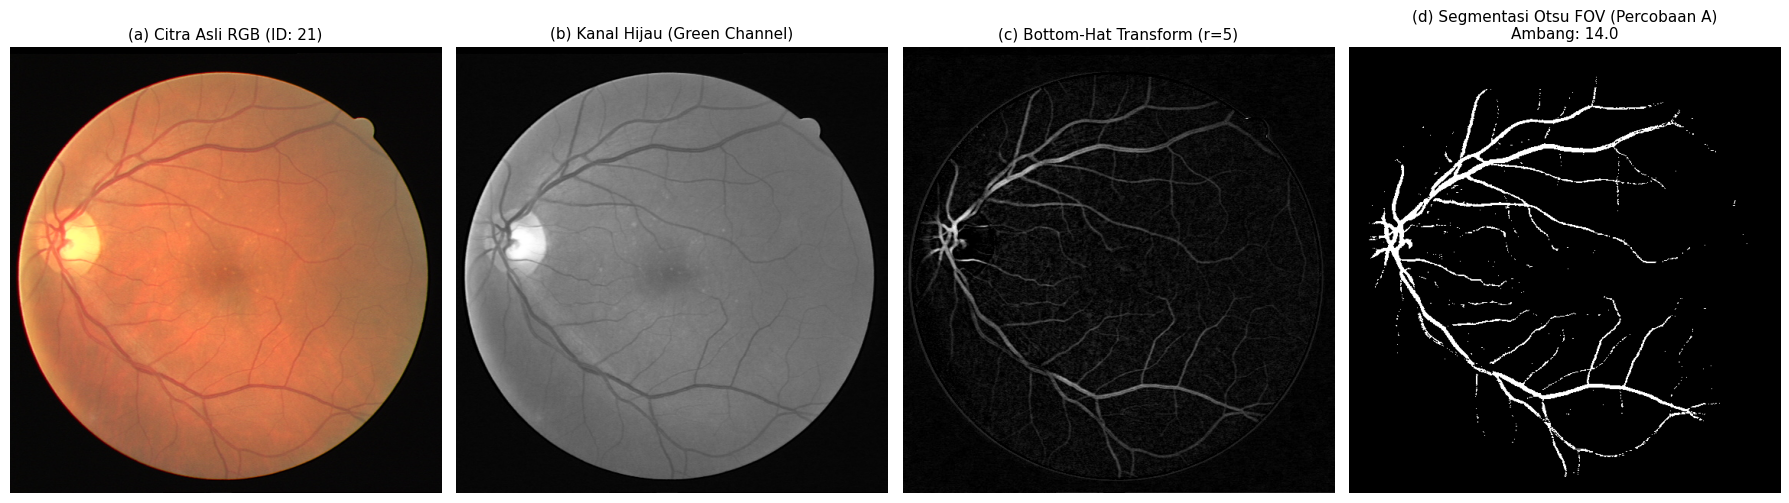

Gambar tahapan tersimpan di: d:\Tugas Kuliah\Semester 5\Analisis Data Citra Biomedik\retinal-vessel-segmentation\hasil\gambar\fig01_tahapan_21_A.png


In [10]:
assert '21' in dev_ids, 'Contoh visual harus berasal dari data pengembangan.'
img_21, man_21, msk_21 = baca_pasangan('21')

pred_21, tahapan_21 = jalankan_percobaan_A(img_21, msk_21, radius_bh=RADIUS_BH)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_21)
axes[0].set_title("(a) Citra Asli RGB (ID: 21)", fontsize=11)
axes[0].axis("off")

axes[1].imshow(tahapan_21["green"], cmap="gray")
axes[1].set_title("(b) Kanal Hijau (Green Channel)", fontsize=11)
axes[1].axis("off")

axes[2].imshow(tahapan_21["bottom_hat"], cmap="gray")
axes[2].set_title(f"(c) Bottom-Hat Transform (r={RADIUS_BH})", fontsize=11)
axes[2].axis("off")

axes[3].imshow(tahapan_21["pred_mask"], cmap="gray")
axes[3].set_title(f"(d) Segmentasi Otsu FOV (Percobaan A)\nAmbang: {tahapan_21['thresh_val']:.1f}", fontsize=11)
axes[3].axis("off")

plt.tight_layout()
fig_out_path = os.path.join(OUTPUT_GAMBAR_DIR, "fig01_tahapan_21_A.png")
plt.savefig(fig_out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gambar tahapan tersimpan di: {fig_out_path}")

### 8.1 Ringkasan hasil awal percobaan A
*(Pelengkap minggu 1: Nad)*
Ringkasan disimpan agar angka untuk laporan berasal langsung dari perhitungan notebook. Simpangan baku menggunakan `ddof=1`. Hasil ini hanya berasal dari 12 citra pengembangan, bukan delapan citra penilaian akhir.

In [11]:
kolom_ringkasan = ['dice', 'iou', 'sensitivity', 'specificity', 'accuracy',
                   'proporsi_area_pred_persen', 'proporsi_area_gt_persen',
                   'selisih_proporsi_poin']
ringkasan_A = df_dev_A[kolom_ringkasan].agg(['mean', 'std', 'min', 'max']).T
ringkasan_A.index.name = 'metrik'
display(ringkasan_A.round(4))
ringkasan_A.to_csv(os.path.join(OUTPUT_TABEL_DIR, 'ringkasan_pengembangan_A.csv'))
print(f"Dice rata-rata: {ringkasan_A.loc['dice', 'mean']:.4f}")
print(f"Sensitivity rata-rata: {ringkasan_A.loc['sensitivity', 'mean']:.4f}")
print(f"Selisih area rata-rata: {ringkasan_A.loc['selisih_proporsi_poin', 'mean']:.2f} poin persentase")

,mean,std,min,max
metrik,,,,
dice,0.6552,0.0560,0.5246,0.7368
iou,0.4895,0.0599,0.3555,0.5832
sensitivity,0.5377,0.0936,0.3687,0.6906
specificity,0.9869,0.0179,0.9380,0.9977
accuracy,0.9302,0.0135,0.9075,0.9457
proporsi_area_pred_persen,7.8900,2.4451,3.5450,13.1229
proporsi_area_gt_persen,12.5635,2.1906,8.7382,16.7811
selisih_proporsi_poin,-4.6735,2.9067,-8.6415,1.7363


Dice rata-rata: 0.6552
Sensitivity rata-rata: 0.5377
Selisih area rata-rata: -4.67 poin persentase


### 8.2 Membandingkan prediksi dengan ground truth
Kita memilih dua contoh dari **data pengembangan**: Dice tertinggi dan terendah. Contoh ini dipilih untuk membahas perbedaan hasil, bukan mewakili seluruh dataset.
Pada overlay, **hijau** menunjukkan pembuluh yang benar (TP), **merah** menunjukkan latar yang salah terambil (FP), dan **biru** menunjukkan pembuluh yang terlewat (FN). Warna hanya ditampilkan dalam FOV.

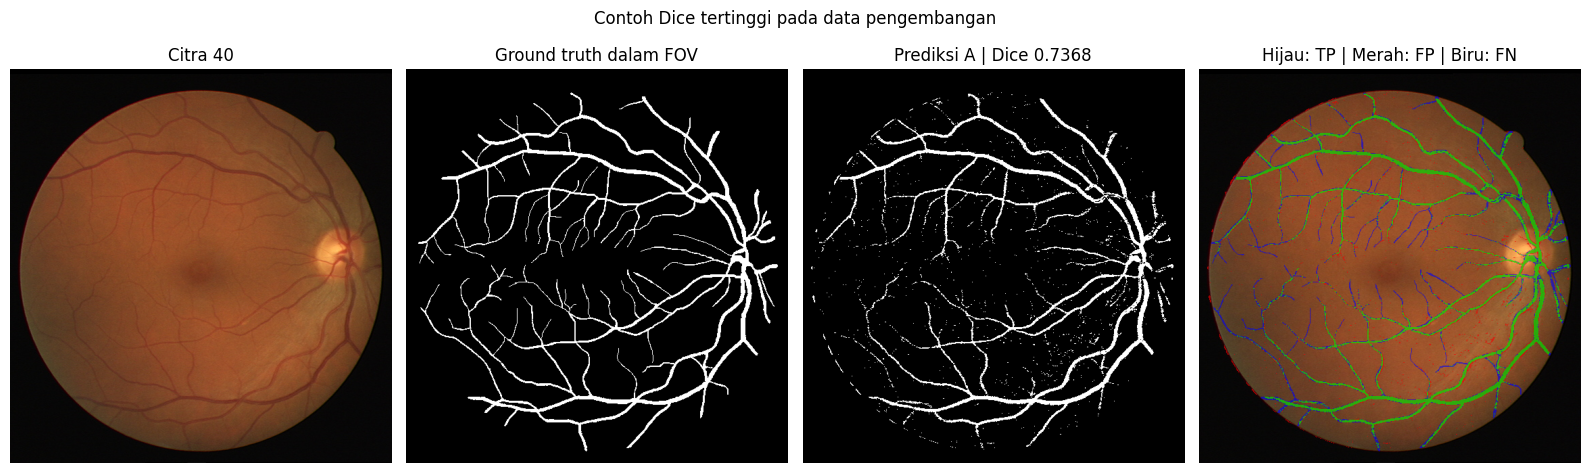

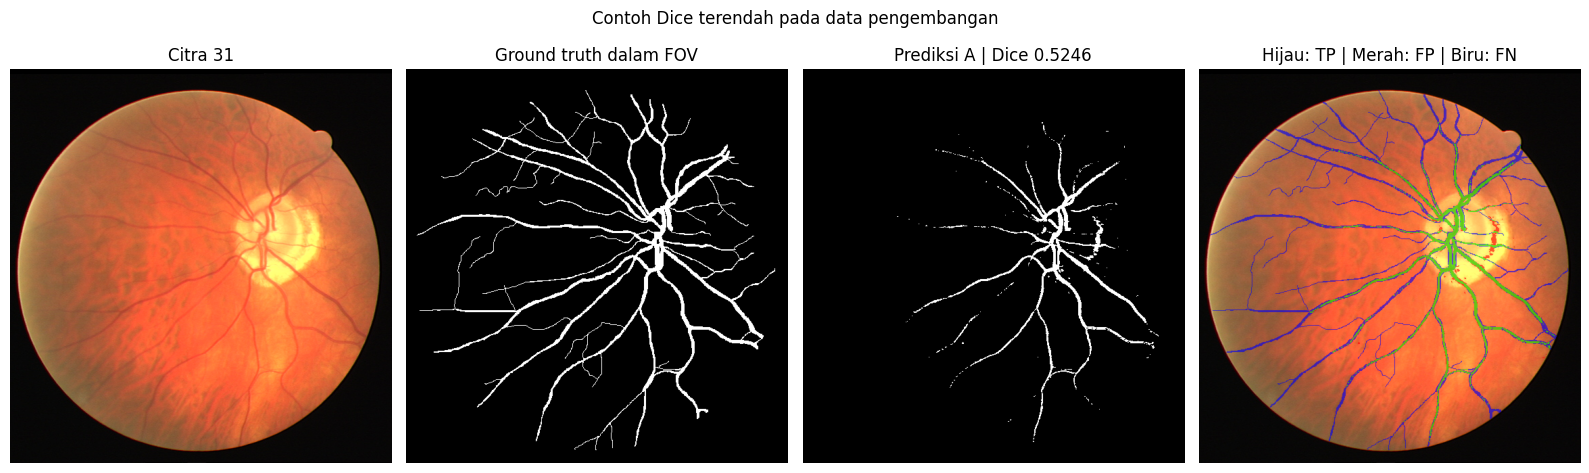

In [12]:
baris_terbaik = df_dev_A.loc[df_dev_A['dice'].idxmax()]
baris_terendah = df_dev_A.loc[df_dev_A['dice'].idxmin()]

for label, baris in [('tertinggi', baris_terbaik), ('terendah', baris_terendah)]:
    id_contoh = str(baris['id'])
    assert id_contoh in dev_ids
    citra, gt, fov = baca_pasangan(id_contoh)
    prediksi, _ = jalankan_percobaan_A(citra, fov, RADIUS_BH)
    area = fov > 0
    tp = (prediksi > 0) & (gt > 0) & area
    fp = (prediksi > 0) & (gt == 0) & area
    fn = (prediksi == 0) & (gt > 0) & area

    # Campurkan warna penanda dengan citra asli agar lokasi tetap terlihat.
    overlay = citra.copy()
    overlay[tp] = (0.4 * citra[tp] + 0.6 * np.array([0, 255, 0])).astype(np.uint8)
    overlay[fp] = (0.4 * citra[fp] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
    overlay[fn] = (0.4 * citra[fn] + 0.6 * np.array([0, 0, 255])).astype(np.uint8)

    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    axes[0].imshow(citra)
    axes[0].set_title(f'Citra {id_contoh}')
    axes[1].imshow(np.where(area, gt, 0), cmap='gray', vmin=0, vmax=255)
    axes[1].set_title('Ground truth dalam FOV')
    axes[2].imshow(prediksi, cmap='gray', vmin=0, vmax=255)
    axes[2].set_title(f"Prediksi A | Dice {baris['dice']:.4f}")
    axes[3].imshow(overlay)
    axes[3].set_title('Hijau: TP | Merah: FP | Biru: FN')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'Contoh Dice {label} pada data pengembangan')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_GAMBAR_DIR, f'overlay_{id_contoh}_A.png'),
                dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 8.3 Catatan hasil minggu 1
Pada baseline radius 5, hasil awal yang sudah diperiksa memiliki Dice rata-rata sekitar 0,6552 dan sensitivity sekitar 0,5377. Artinya, masih banyak piksel pembuluh yang belum terambil. Proporsi area prediksi rata-rata lebih kecil daripada acuan, dengan selisih sekitar −4,67 poin persentase. Angka tersebut berlaku untuk konfigurasi awal; jika parameter diubah, baca kembali ringkasan di atas.

Accuracy yang tinggi tidak cukup untuk menyatakan hasil sudah baik karena piksel latar lebih banyak daripada pembuluh. Gunakan overlay untuk memeriksa lokasi pembuluh yang terlewat dan latar yang salah terambil. Kita belum dapat menyimpulkan bahwa CLAHE, median, atau closing akan memperbaiki hasil sebelum percobaan B/C dilakukan pada minggu kedua.

## 9. Pemutakhiran Daftar Rujukan dan Tinjauan Laporan Inisiasi
*(Tanggung jawab: Kayo)*  
Berdasarkan tinjauan terhadap naskah `Kelompok5_ProjekTahap1.docx`, terdapat sitasi `[1]`, `[3]`, `[4]`, dan `[5]` yang perlu dilengkapi identitas bibliografinya secara resmi agar laporan inisiasi utuh:

1. **[1] Dataset DRIVE:**  
   DRIVE: Digital Retinal Images for Vessel Extraction. Grand Challenge Project. URL: https://drive.grand-challenge.org/
2. **[2] Metode Ridge & Evaluasi DRIVE:**  
   Staal, J., Abramoff, M. D., Niemeijer, M., Viergever, M. A., & van Ginneken, B. (2004). *Ridge-based vessel segmentation in color images of the retina*. IEEE Transactions on Medical Imaging, 23(4), 501–509. https://doi.org/10.1109/TMI.2004.825627
3. **[3] Thresholding Otsu:**  
   Otsu, N. (1979). *A threshold selection method from gray-level histograms*. IEEE Transactions on Systems, Man, and Cybernetics, 9(1), 62–66. https://doi.org/10.1109/TSMC.1979.4310076
4. **[4] Top-Hat & Bottom-Hat Enhancement:**  
   Mendonça, A. M., & Campilho, A. (2006). *Segmentation of retinal blood vessels by combining the detection of multiscale features*. IEEE Transactions on Medical Imaging, 25(9), 1200–1210. https://doi.org/10.1109/TMI.2006.879955
5. **[5] Morfologi Matematika & Thresholding:**  
   Fraz, M. M., Remagnino, P., Hoppe, A., Uyyanonvara, B., Rudnicka, A. R., Owen, C. G., & Barman, S. A. (2012). *Blood vessel segmentation methodologies in retinal images – a survey*. Computer Methods and Programs in Biomedicine, 108(1), 407–433. https://doi.org/10.1016/j.cmpb.2012.03.009